Training EfficientDet-D0 (BASELINE / Tanpa Optimasi) untuk Object Counting (Smart Classroom)

## Step 0 — Setup Environment

### Cek GPU


In [ ]:
# Mengecek ketersediaan dan tipe GPU yang dialokasikan Colab untuk sesi ini
!nvidia-smi


Sat Jul 18 19:47:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   37C    P0             55W /  400W |       0MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

### Mount Google Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


### Install Library

- `effdet`  : implementasi EfficientDet berbasis PyTorch (rwightman), mendukung varian D0 - D7
- `pycocotools` : membaca anotasi format COCO dan menghitung metrik mAP standar
- `timm`    : backbone EfficientNet yang digunakan di dalam EfficientDet
- `omegaconf` : dependency konfigurasi yang dibutuhkan `effdet`
- `thop`    : menghitung GFLOPs dan jumlah parameter model


In [ ]:
!pip install -q effdet pycocotools timm omegaconf thop


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.5/112.5 kB 9.9 MB/s eta 0:00:00


### Import Library & Set Seed


In [ ]:
import os
import json
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader

from effdet import EfficientDet, DetBenchTrain, DetBenchPredict, get_efficientdet_config
from effdet.efficientdet import HeadNet

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

from thop import profile


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Menggunakan device: {device}")


Menggunakan device: cuda


## Step 1 — Konfigurasi Path Dataset & Hyperparameter

Perhatikan bagian hyperparameter di bawah jauh lebih sederhana dibanding notebook D0/D1 yang sudah dioptimasi — **tidak ada** `LR_CANDIDATES`, `WARMUP_EPOCHS`, atau `EARLY_STOPPING_PATIENCE`, karena semua fitur itu memang sengaja tidak dipakai di versi baseline ini.


In [ ]:
# ==== SESUAIKAN BAGIAN INI SESUAI LOKASI DATASET ANDA ====
DATASET_ROOT = '/content/drive/MyDrive/Classroom Dataset/Ruang Kelas COCO'

TRAIN_DIR = os.path.join(DATASET_ROOT, 'train')
VALID_DIR = os.path.join(DATASET_ROOT, 'valid')
TEST_DIR  = os.path.join(DATASET_ROOT, 'test')

TRAIN_ANN = os.path.join(TRAIN_DIR, '_annotations.coco.json')
VALID_ANN = os.path.join(VALID_DIR, '_annotations.coco.json')
TEST_ANN  = os.path.join(TEST_DIR, '_annotations.coco.json')

# Folder untuk menyimpan checkpoint & hasil training (terpisah dari folder D0 Optimized / D1)
OUTPUT_DIR = os.path.join(DATASET_ROOT, 'efficientdet_d0_baseline_outputs')
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ==== HYPERPARAMETER (SEMUA NILAI TETAP, TIDAK ADA YANG DI-TUNING) ====
MODEL_NAME     = 'tf_efficientdet_d0'
IMAGE_SIZE     = 640
NUM_CLASSES    = 2
BATCH_SIZE     = 16
NUM_EPOCHS     = 100
LEARNING_RATE  = 1e-4
PATIENCE       = 50
WEIGHT_DECAY   = 0.0
NUM_WORKERS    = 2

# ==== CONFIDENCE THRESHOLD ====
CONF_THRESHOLD = 0.3
IOU_THRESHOLD  = 0.5

print("Dataset root :", DATASET_ROOT)
print("Output dir   :", OUTPUT_DIR)


Dataset root : /content/drive/MyDrive/Classroom Dataset/Ruang Kelas COCO
Output dir   : /content/drive/MyDrive/Classroom Dataset/Ruang Kelas COCO/efficientdet_d0_baseline_outputs


## Step 2 — Dataset & DataLoader (format COCO)

Class `ClassroomDataset` bertugas:
1. Membaca file `_annotations.coco.json` menggunakan `pycocotools`
2. Memuat gambar dan bounding box sesuai id gambar
3. Mengonversi bounding box dari format COCO `[x, y, w, h]` ke format yang dibutuhkan EfficientDet, yaitu `[y_min, x_min, y_max, x_max]`
4. Melakukan **padding** gambar menjadi persis 640x640 (ditempel di pojok kiri-atas, tanpa distorsi/stretch) — murni penyesuaian teknis agar bisa di-batch, **bukan augmentasi data baru**
5. Mengembalikan tensor gambar + target dict (bbox, label kelas, image_id, dll) sesuai format yang dibutuhkan library `effdet`

**Penting:** label kelas di `effdet` menggunakan indeks mulai dari **1** (bukan 0). Mapping kelas akan otomatis dicetak agar Anda bisa memverifikasi urutan `table` dan `person`.


In [ ]:
class ClassroomDataset(Dataset):
    def __init__(self, images_dir, ann_path, image_size=640):
        self.images_dir = images_dir
        self.image_size = image_size
        self.coco = COCO(ann_path)
        self.image_ids = list(sorted(self.coco.imgs.keys()))

        # Bangun mapping category_id (COCO asli) -> label EfficientDet (mulai dari 1)
        cat_ids = sorted(self.coco.getCatIds())
        self.cat_id_to_label = {cat_id: i + 1 for i, cat_id in enumerate(cat_ids)}
        self.label_to_cat_id = {v: k for k, v in self.cat_id_to_label.items()}
        self.label_to_name = {
            self.cat_id_to_label[c['id']]: c['name']
            for c in self.coco.loadCats(cat_ids)
        }
        print("Mapping kelas -> label EfficientDet:", self.label_to_name)

        self.imagenet_mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        self.imagenet_std  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        img_info = self.coco.loadImgs(image_id)[0]
        img_path = os.path.join(self.images_dir, img_info['file_name'])
        image = Image.open(img_path).convert('RGB')

        ann_ids = self.coco.getAnnIds(imgIds=image_id)
        anns = self.coco.loadAnns(ann_ids)

        boxes = []
        labels = []
        for ann in anns:
            x, y, w, h = ann['bbox']
            if w <= 0 or h <= 0:
                continue
            # konversi ke [y_min, x_min, y_max, x_max] sesuai kebutuhan effdet
            boxes.append([y, x, y + h, x + w])
            labels.append(self.cat_id_to_label[ann['category_id']])

        # Tempel gambar ke kanvas persis image_size x image_size di pojok kiri-atas
        # Koordinat box tidak perlu diubah karena offset penempelan adalah (0, 0)
        canvas = Image.new('RGB', (self.image_size, self.image_size))
        canvas.paste(image, (0, 0))
        image_arr = np.array(canvas, dtype=np.float32) / 255.0
        image_arr = (image_arr - self.imagenet_mean) / self.imagenet_std
        image_tensor = torch.from_numpy(image_arr).permute(2, 0, 1).float()

        if len(boxes) == 0:
            boxes_arr = np.zeros((0, 4), dtype=np.float32)
            labels_arr = np.zeros((0,), dtype=np.int64)
        else:
            boxes_arr = np.array(boxes, dtype=np.float32)
            labels_arr = np.array(labels, dtype=np.int64)

        target = {
            'bbox': torch.as_tensor(boxes_arr, dtype=torch.float32),
            'cls': torch.as_tensor(labels_arr, dtype=torch.int64),
            'image_id': torch.tensor([image_id]),
            'img_scale': torch.tensor([1.0], dtype=torch.float32),
            'img_size': torch.tensor([(self.image_size, self.image_size)], dtype=torch.float32),
        }
        return image_tensor, target


### DataLoader & Collate Function

Karena jumlah bounding box tiap gambar berbeda-beda, dibutuhkan `collate_fn` khusus untuk menyusun batch.


In [ ]:
def collate_fn(batch):
    images = torch.stack([item[0] for item in batch])
    targets = [item[1] for item in batch]
    batch_target = {
        'bbox': [t['bbox'] for t in targets],
        'cls': [t['cls'] for t in targets],
        'image_id': torch.cat([t['image_id'] for t in targets]),
        'img_scale': torch.cat([t['img_scale'] for t in targets]),
        'img_size': torch.cat([t['img_size'] for t in targets]),
    }
    return images, batch_target, targets  # 'targets' asli disertakan untuk kebutuhan evaluasi lanjutan


train_dataset = ClassroomDataset(TRAIN_DIR, TRAIN_ANN, IMAGE_SIZE)
valid_dataset = ClassroomDataset(VALID_DIR, VALID_ANN, IMAGE_SIZE)
test_dataset  = ClassroomDataset(TEST_DIR, TEST_ANN, IMAGE_SIZE)

# Cek kesesuaian jumlah data dengan komposisi yang direncanakan (1050 / 100 / 50)
expected_counts = {'train': 1050, 'valid': 100, 'test': 50}
actual_counts = {'train': len(train_dataset), 'valid': len(valid_dataset), 'test': len(test_dataset)}
for split, expected in expected_counts.items():
    actual = actual_counts[split]
    status = "OK" if actual == expected else "PERIKSA KEMBALI"
    print(f"[{status}] Jumlah data {split}: {actual} (target: {expected})")

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=NUM_WORKERS, collate_fn=collate_fn, drop_last=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False,
                           num_workers=NUM_WORKERS, collate_fn=collate_fn)
test_loader  = DataLoader(test_dataset, batch_size=1, shuffle=False,
                           num_workers=NUM_WORKERS, collate_fn=collate_fn)


loading annotations into memory...
Done (t=4.59s)
creating index...
index created!
Mapping kelas -> label EfficientDet: {1: 'person', 2: 'table'}
loading annotations into memory...
Done (t=1.46s)
creating index...
index created!
Mapping kelas -> label EfficientDet: {1: 'person', 2: 'table'}
loading annotations into memory...
Done (t=1.30s)
creating index...
index created!
Mapping kelas -> label EfficientDet: {1: 'person', 2: 'table'}
[OK] Jumlah data train: 1050 (target: 1050)
[OK] Jumlah data valid: 100 (target: 100)
[OK] Jumlah data test: 50 (target: 50)


## Step 3 — Sanity Check: Visualisasi Sample Data



In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def denormalize(image_tensor, mean, std):
    img = image_tensor.permute(1, 2, 0).cpu().numpy()
    img = img * std + mean
    return np.clip(img, 0, 1)


def show_samples(dataset, num_samples=4):

    # warna untuk setiap kelas
    COLOR_MAP = {
        "person": "lime",
        "table": "red"
    }

    fig, axes = plt.subplots(1, num_samples, figsize=(6*num_samples,6))

    indices = random.sample(range(len(dataset)), num_samples)

    for ax, idx in zip(axes, indices):

        image_tensor, target = dataset[idx]
        img = denormalize(
            image_tensor,
            dataset.imagenet_mean,
            dataset.imagenet_std
        )

        ax.imshow(img)

        for box, label in zip(target["bbox"], target["cls"]):

            y1, x1, y2, x2 = box.tolist()

            class_name = dataset.label_to_name[int(label)]

            color = COLOR_MAP.get(class_name, "yellow")

            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=2,
                edgecolor=color,
                facecolor="none"
            )

            ax.add_patch(rect)

            ax.text(
                x1,
                max(y1-3,0),
                class_name,
                fontsize=6,
                color="white",
                bbox=dict(
                    facecolor=color,
                    alpha=0.7,
                    edgecolor="none",
                    pad=0.3
                )
            )

        ax.axis("off")

    plt.tight_layout()
    plt.show()

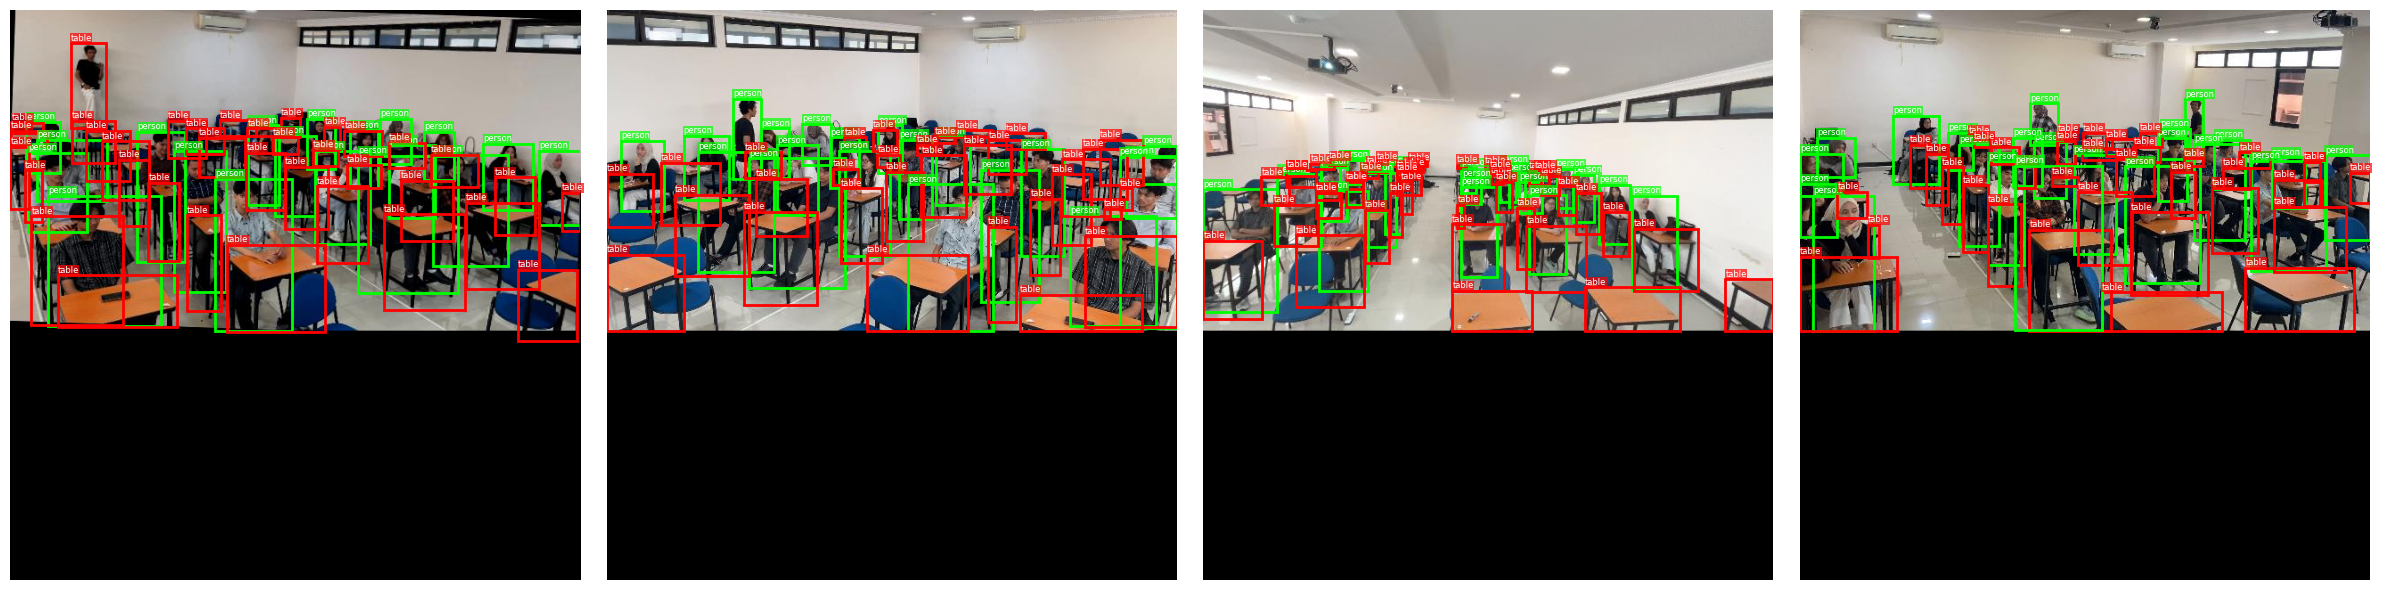

In [ ]:
show_samples(train_dataset, num_samples=4)

## Step 4 — Membangun Model EfficientDet-D0



In [ ]:
def build_model(num_classes, image_size, model_name='tf_efficientdet_d0', pretrained=True):
    config = get_efficientdet_config(model_name)
    config.image_size = (image_size, image_size)
    config.num_classes = num_classes

    net = EfficientDet(config, pretrained_backbone=pretrained)
    net.class_net = HeadNet(config, num_outputs=num_classes)
    return net, config


net, model_config = build_model(NUM_CLASSES, IMAGE_SIZE, MODEL_NAME, pretrained=True)
train_bench = DetBenchTrain(net, model_config).to(device)

total_params = sum(p.numel() for p in net.parameters())
trainable_params = sum(p.numel() for p in net.parameters() if p.requires_grad)
print(f"Total parameter model : {total_params:,}")
print(f"Parameter trainable   : {trainable_params:,}")


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Total parameter model : 3,828,587
Parameter trainable   : 3,828,587


## Step 5 — Optimizer


In [ ]:
optimizer = torch.optim.AdamW(train_bench.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
print(f"Optimizer: AdamW, learning rate tetap = {LEARNING_RATE} (tanpa scheduler)")


Optimizer: AdamW, learning rate tetap = 0.0001 (tanpa scheduler)


## Step 6 — Fungsi Training & Validasi per Epoch


In [ ]:
def train_one_epoch(model, loader, optimizer, device):
    model.train()
    running_loss = 0.0
    for images, batch_target, _ in loader:
        images = images.to(device)
        target = {
            'bbox': [b.to(device) for b in batch_target['bbox']],
            'cls': [c.to(device) for c in batch_target['cls']],
            'image_id': batch_target['image_id'].to(device),
            'img_scale': batch_target['img_scale'].to(device),
            'img_size': batch_target['img_size'].to(device),
        }
        optimizer.zero_grad()
        losses = model(images, target)
        loss = losses['loss']
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    return running_loss / len(loader)


@torch.no_grad()
def validate(model, loader, device):
    model.eval()
    running_loss = 0.0
    for images, batch_target, _ in loader:
        images = images.to(device)
        target = {
            'bbox': [b.to(device) for b in batch_target['bbox']],
            'cls': [c.to(device) for c in batch_target['cls']],
            'image_id': batch_target['image_id'].to(device),
            'img_scale': batch_target['img_scale'].to(device),
            'img_size': batch_target['img_size'].to(device),
        }
        losses = model(images, target)
        running_loss += losses['loss'].item()
    return running_loss / len(loader)


## Step 7 — Main Training Loop




In [ ]:
history = {
    'train_loss': [],
    'val_loss': []
}

best_val_loss = float('inf')

best_ckpt_path = os.path.join(
    OUTPUT_DIR,
    'efficientdet_d0_baseline_best.pth'
)

# Counter untuk Early Stopping
epochs_no_improve = 0

start_time = time.time()

for epoch in range(1, NUM_EPOCHS + 1):

    epoch_start = time.time()

    # ========================================================
    # TRAINING
    # ========================================================
    train_loss = train_one_epoch(
        train_bench,
        train_loader,
        optimizer,
        device
    )

    # ========================================================
    # VALIDATION
    # ========================================================
    val_loss = validate(
        train_bench,
        valid_loader,
        device
    )

    # Simpan history
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch [{epoch}/{NUM_EPOCHS}] "
        f"train_loss={train_loss:.4f}  "
        f"val_loss={val_loss:.4f}  "
        f"lr={LEARNING_RATE:.6f} (tetap)  "
        f"waktu={epoch_time:.1f}s"
    )

    # ========================================================
    # CEK PERBAIKAN VALIDATION LOSS
    # ========================================================
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        # Reset counter Early Stopping
        epochs_no_improve = 0

        # Simpan model terbaik
        torch.save(
            net.state_dict(),
            best_ckpt_path
        )

        print(
            f"  -> Model terbaik disimpan "
            f"(val_loss={val_loss:.4f}) "
            f"di {best_ckpt_path}"
        )

    else:

        # Tambah counter jika tidak ada perbaikan
        epochs_no_improve += 1

        print(
            f"  -> Tidak ada perbaikan val_loss "
            f"({epochs_no_improve}/{PATIENCE})"
        )

    # ========================================================
    # EARLY STOPPING
    # ========================================================
    if epochs_no_improve >= PATIENCE:

        print(
            f"\nEarly Stopping aktif pada epoch {epoch}."
        )

        print(
            f"Tidak ada perbaikan val_loss selama "
            f"{PATIENCE} epoch berturut-turut."
        )

        print(
            f"Best validation loss: "
            f"{best_val_loss:.4f}"
        )

        break


# ============================================================
# TOTAL WAKTU TRAINING
# ============================================================
total_time = time.time() - start_time

# Jumlah epoch yang benar-benar dijalankan
actual_epochs = len(history['train_loss'])

print(
    f"\nTotal waktu training: "
    f"{total_time/60:.1f} menit "
    f"({actual_epochs} epoch dijalankan)"
)


# ============================================================
# SIMPAN TRAINING HISTORY
# ============================================================
with open(
    os.path.join(
        OUTPUT_DIR,
        'training_history.json'
    ),
    'w'
) as f:

    json.dump(
        history,
        f,
        indent=2
    )

print(
    f"Model terbaik tersimpan di: "
    f"{best_ckpt_path}"
)

Epoch [1/100] train_loss=29.1614  val_loss=29.5413  lr=0.000100 (tetap)  waktu=372.0s
  -> Model terbaik disimpan (val_loss=29.5413) di /content/drive/MyDrive/Classroom Dataset/Ruang Kelas COCO/efficientdet_d0_baseline_outputs/efficientdet_d0_baseline_best.pth
Epoch [2/100] train_loss=26.0866  val_loss=29.0713  lr=0.000100 (tetap)  waktu=20.4s
  -> Model terbaik disimpan (val_loss=29.0713) di /content/drive/MyDrive/Classroom Dataset/Ruang Kelas COCO/efficientdet_d0_baseline_outputs/efficientdet_d0_baseline_best.pth
Epoch [3/100] train_loss=22.8536  val_loss=27.9888  lr=0.000100 (tetap)  waktu=19.4s
  -> Model terbaik disimpan (val_loss=27.9888) di /content/drive/MyDrive/Classroom Dataset/Ruang Kelas COCO/efficientdet_d0_baseline_outputs/efficientdet_d0_baseline_best.pth
Epoch [4/100] train_loss=19.4097  val_loss=24.8194  lr=0.000100 (tetap)  waktu=19.2s
  -> Model terbaik disimpan (val_loss=24.8194) di /content/drive/MyDrive/Classroom Dataset/Ruang Kelas COCO/efficientdet_d0_baseline_o

## Step 8 — Plot Kurva Training & Validation Loss



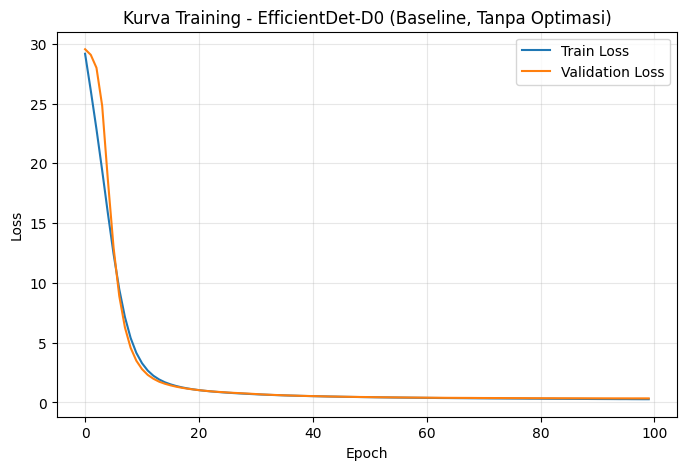

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Kurva Training - EfficientDet-D0 (Baseline, Tanpa Optimasi)')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, 'loss_curve.png'), dpi=150, bbox_inches='tight')
plt.show()


## Step 9 — Evaluasi mAP@50-95 pada Test Set

Menggunakan `DetBenchPredict` untuk menghasilkan prediksi pada seluruh gambar test, lalu menghitung mAP dengan `pycocotools.COCOeval`. `summarize()` tetap mencetak semua metrik standar COCO ke layar (perilaku bawaan library), namun **hanya `mAP_50` yang diambil dan dilaporkan**, sesuai scope evaluasi yang disamakan dengan notebook D0 Optimized.

Prediksi yang dipakai untuk mAP memakai threshold sangat rendah (`MAP_EVAL_THRESHOLD = 0.001`), bukan `CONF_THRESHOLD`, karena mAP mengintegrasikan seluruh kurva precision-recall di berbagai level confidence.


In [ ]:
# ==========================================================
# LOAD MODEL TERBAIK
# ==========================================================
net.load_state_dict(torch.load(best_ckpt_path, map_location=device))

predict_bench = DetBenchPredict(net).to(device)
predict_bench.eval()

# Threshold rendah agar seluruh prediksi digunakan saat evaluasi COCO
MAP_EVAL_THRESHOLD = 0.001

coco_results = []

# ==========================================================
# INFERENCE PADA TEST SET
# ==========================================================
with torch.no_grad():

    for images, batch_target, targets in test_loader:

        images = images.to(device)

        img_size_tensor = batch_target['img_size'].to(device)
        img_scale_tensor = batch_target['img_scale'].to(device)

        detections = predict_bench(
            images,
            {
                'img_size': img_size_tensor,
                'img_scale': img_scale_tensor
            }
        )

        det = detections[0].cpu().numpy()

        image_id = int(targets[0]['image_id'].item())

        for x1, y1, x2, y2, score, label_effdet in det:

            if score < MAP_EVAL_THRESHOLD:
                continue

            w = x2 - x1
            h = y2 - y1

            coco_results.append({
                "image_id": image_id,
                "category_id": test_dataset.label_to_cat_id[int(label_effdet)],
                "bbox": [
                    float(x1),
                    float(y1),
                    float(w),
                    float(h)
                ],
                "score": float(score)
            })

# ==========================================================
# SIMPAN HASIL PREDIKSI
# ==========================================================
results_path = os.path.join(
    OUTPUT_DIR,
    "test_predictions_coco.json"
)

with open(results_path, "w") as f:
    json.dump(coco_results, f)

# ==========================================================
# EVALUASI COCO
# ==========================================================
coco_gt = test_dataset.coco
coco_dt = coco_gt.loadRes(results_path)

coco_eval = COCOeval(
    coco_gt,
    coco_dt,
    iouType="bbox"
)

coco_eval.evaluate()
coco_eval.accumulate()
coco_eval.summarize()

# ==========================================================
# AMBIL METRIK mAP
# ==========================================================
mAP_50_95 = coco_eval.stats[0]   # AP@[0.50:0.95]
mAP_50 = coco_eval.stats[1]      # AP@0.50

# ==========================================================
# HITUNG MEAN PRECISION DAN MEAN RECALL
# ==========================================================
precision = coco_eval.eval["precision"]
recall = coco_eval.eval["recall"]

valid_precision = precision[precision > -1]
valid_recall = recall[recall > -1]

mean_precision = (
    valid_precision.mean()
    if len(valid_precision) > 0
    else 0.0
)

mean_recall = (
    valid_recall.mean()
    if len(valid_recall) > 0
    else 0.0
)

# ==========================================================
# HASIL EVALUASI
# ==========================================================
print("\n" + "=" * 50)
print("           HASIL EVALUASI TEST SET")
print("=" * 50)

print(f"Precision (mP) : {mean_precision:.4f}")
print(f"Recall (mR)    : {mean_recall:.4f}")
print(f"mAP@50         : {mAP_50:.4f}")
print(f"mAP@50-95      : {mAP_50_95:.4f}")

print("=" * 50)

Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=2.04s).
Accumulating evaluation results...
DONE (t=0.05s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.346
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.641
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.332
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.175
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.430
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.588
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.027
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.225
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.426
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

## Step 10 — Confusion Matrix



Confusion Matrix (baris = ground truth, kolom = prediksi):
            person  table  background
person         769     15         243
table           30    891         685
background     517    509           0


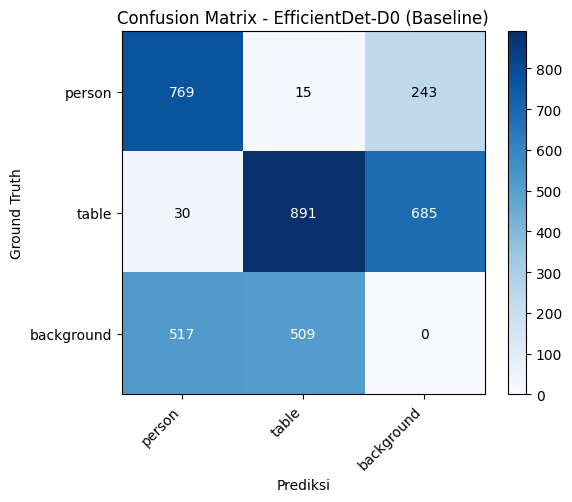

In [ ]:
def compute_iou(box1, box2):
    # format box: [x1, y1, x2, y2]
    xx1 = max(box1[0], box2[0])
    yy1 = max(box1[1], box2[1])
    xx2 = min(box1[2], box2[2])
    yy2 = min(box1[3], box2[3])

    inter_w = max(0.0, xx2 - xx1)
    inter_h = max(0.0, yy2 - yy1)
    inter_area = inter_w * inter_h

    area1 = max(0.0, box1[2] - box1[0]) * max(0.0, box1[3] - box1[1])
    area2 = max(0.0, box2[2] - box2[0]) * max(0.0, box2[3] - box2[1])
    union_area = area1 + area2 - inter_area
    if union_area <= 0:
        return 0.0
    return inter_area / union_area


class_names_ordered = [test_dataset.label_to_name[i + 1] for i in range(NUM_CLASSES)]
all_names = class_names_ordered + ['background']
n_labels = len(all_names)
BACKGROUND_IDX = n_labels - 1

confusion_matrix = np.zeros((n_labels, n_labels), dtype=int)

predict_bench.eval()
with torch.no_grad():
    for images, batch_target, targets in test_loader:
        images = images.to(device)
        img_size = batch_target['img_size'].to(device)
        img_scale = batch_target['img_scale'].to(device)
        detections = predict_bench(images, {'img_size': img_size, 'img_scale': img_scale})

        det = detections[0].cpu().numpy()
        det = det[det[:, 4] >= CONF_THRESHOLD]
        det = det[det[:, 4].argsort()[::-1]]  # urutkan dari confidence tertinggi

        gt_boxes = targets[0]['bbox'].numpy()   # format [y1, x1, y2, x2]
        gt_labels = targets[0]['cls'].numpy()
        matched_gt = np.zeros(len(gt_boxes), dtype=bool)

        for x1, y1, x2, y2, score, pred_label in det:
            pred_idx = int(pred_label) - 1
            best_iou, best_gi = 0.0, -1
            for gi, gt_box in enumerate(gt_boxes):
                if matched_gt[gi]:
                    continue
                gy1, gx1, gy2, gx2 = gt_box
                iou = compute_iou([x1, y1, x2, y2], [gx1, gy1, gx2, gy2])
                if iou > best_iou:
                    best_iou, best_gi = iou, gi

            if best_iou >= IOU_THRESHOLD:
                matched_gt[best_gi] = True
                gt_idx = int(gt_labels[best_gi]) - 1
                confusion_matrix[gt_idx, pred_idx] += 1
            else:
                confusion_matrix[BACKGROUND_IDX, pred_idx] += 1

        for gi, matched in enumerate(matched_gt):
            if not matched:
                gt_idx = int(gt_labels[gi]) - 1
                confusion_matrix[gt_idx, BACKGROUND_IDX] += 1

cm_df = pd.DataFrame(confusion_matrix, index=all_names, columns=all_names)
print("Confusion Matrix (baris = ground truth, kolom = prediksi):")
print(cm_df)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(confusion_matrix, cmap='Blues')
ax.set_xticks(range(n_labels))
ax.set_xticklabels(all_names, rotation=45, ha='right')
ax.set_yticks(range(n_labels))
ax.set_yticklabels(all_names)
ax.set_xlabel('Prediksi')
ax.set_ylabel('Ground Truth')
ax.set_title('Confusion Matrix - EfficientDet-D0 (Baseline)')
for i in range(n_labels):
    for j in range(n_labels):
        color = 'white' if confusion_matrix[i, j] > confusion_matrix.max() / 2 else 'black'
        ax.text(j, i, confusion_matrix[i, j], ha='center', va='center', color=color)
plt.colorbar(im)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()

cm_df.to_csv(os.path.join(OUTPUT_DIR, 'confusion_matrix.csv'))


## Step 11 — Mengukur FPS (Kecepatan Inferensi)




In [ ]:
def measure_fps(predict_bench, dataset, device, num_warmup=10, num_iterations=100):
    predict_bench.eval()

    image_tensor, target = dataset[0]
    images = image_tensor.unsqueeze(0).to(device)
    img_info = {
        'img_size': target['img_size'].to(device),
        'img_scale': target['img_scale'].to(device),
    }

    with torch.no_grad():
        for _ in range(num_warmup):
            _ = predict_bench(images, img_info)
            if device.type == 'cuda':
                torch.cuda.synchronize()

    timings = []
    with torch.no_grad():
        for _ in range(num_iterations):
            if device.type == 'cuda':
                torch.cuda.synchronize()
            start = time.time()

            _ = predict_bench(images, img_info)

            if device.type == 'cuda':
                torch.cuda.synchronize()
            end = time.time()
            timings.append(end - start)

    avg_time_sec = np.mean(timings)
    std_time_sec = np.std(timings)
    fps = 1.0 / avg_time_sec

    print(f"Rata-rata waktu inferensi : {avg_time_sec * 1000:.2f} ms (+/- {std_time_sec * 1000:.2f} ms)")
    print(f"FPS (batch size = 1)      : {fps:.2f} frame/detik")
    print(f"Device                    : {device} ({torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU'})")

    return {
        'avg_inference_time_ms': float(avg_time_sec * 1000),
        'std_inference_time_ms': float(std_time_sec * 1000),
        'fps': float(fps),
        'device': str(device),
        'device_name': torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU',
    }


fps_results = measure_fps(predict_bench, test_dataset, device, num_warmup=10, num_iterations=100)

with open(os.path.join(OUTPUT_DIR, 'fps_results.json'), 'w') as f:
    json.dump(fps_results, f, indent=2)


Rata-rata waktu inferensi : 29.75 ms (+/- 0.72 ms)
FPS (batch size = 1)      : 33.62 frame/detik
Device                    : cuda (NVIDIA A100-SXM4-80GB)


## Step 12 — Evaluasi Object Counting: MAE



In [ ]:
def count_objects_per_class(cls_array, label_to_name):
    counts = {name: 0 for name in label_to_name.values()}
    for c in cls_array:
        name = label_to_name.get(int(c))
        if name is not None:
            counts[name] += 1
    return counts


gt_counts_list = []
pred_counts_list = []

predict_bench.eval()
with torch.no_grad():
    for images, batch_target, targets in test_loader:
        images = images.to(device)
        img_size_tensor = batch_target['img_size'].to(device)
        img_scale_tensor = batch_target['img_scale'].to(device)

        detections = predict_bench(images, {'img_size': img_size_tensor, 'img_scale': img_scale_tensor})
        det = detections[0].cpu().numpy()
        pred_classes = det[det[:, 4] >= CONF_THRESHOLD][:, 5]

        gt_classes = targets[0]['cls'].numpy()

        gt_counts_list.append(count_objects_per_class(gt_classes, test_dataset.label_to_name))
        pred_counts_list.append(count_objects_per_class(pred_classes, test_dataset.label_to_name))

gt_df = pd.DataFrame(gt_counts_list)
pred_df = pd.DataFrame(pred_counts_list)

counting_metrics = {}
for class_name in gt_df.columns:
    diff = gt_df[class_name] - pred_df[class_name]
    mae = diff.abs().mean()
    counting_metrics[class_name] = {'MAE': float(mae)}
    print(f"Kelas '{class_name}': MAE = {mae:.3f}")

all_diffs = pd.concat([gt_df[c] - pred_df[c] for c in gt_df.columns])
overall_mae = all_diffs.abs().mean()
print(f"\nMAE keseluruhan (semua kelas): {overall_mae:.3f}")
counting_metrics['overall'] = {'MAE': float(overall_mae)}

with open(os.path.join(OUTPUT_DIR, 'counting_metrics.json'), 'w') as f:
    json.dump(counting_metrics, f, indent=2)


Kelas 'person': MAE = 5.860
Kelas 'table': MAE = 5.660

MAE keseluruhan (semua kelas): 5.760


## Step 13 — GFLOPs & Jumlah Parameter Model



In [ ]:
dummy_input = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE).to(device)
net.eval()
with torch.no_grad():
    macs, params = profile(net, inputs=(dummy_input,), verbose=False)

gflops = (2 * macs) / 1e9   # 1 MAC = 2 FLOPs
params_million = params / 1e6

print(f"GFLOPs            : {gflops:.2f} GFLOPs")
print(f"Jumlah Parameter   : {int(params):,} ({params_million:.2f} juta)")

with open(os.path.join(OUTPUT_DIR, 'model_complexity.json'), 'w') as f:
    json.dump({'gflops': float(gflops), 'num_parameters': int(params)}, f, indent=2)


GFLOPs            : 6.68 GFLOPs
Jumlah Parameter   : 3,764,786 (3.76 juta)


## Step 14 — Simulasi Counting & Visualisasi Hasil



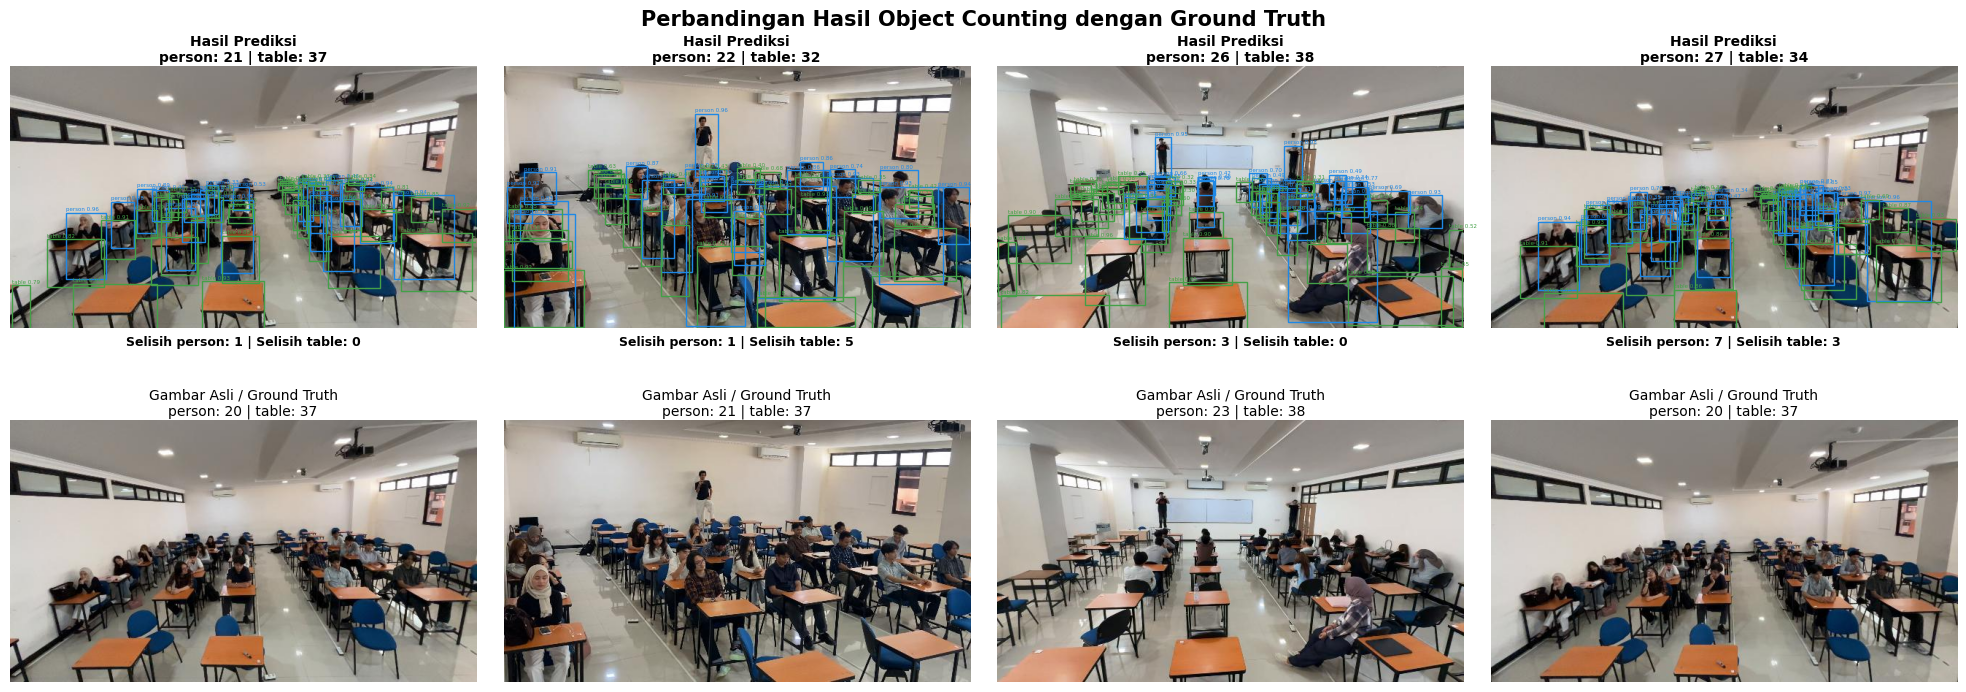


RINGKASAN SIMULASI OBJECT COUNTING
person  : Ground Truth =  84 | Prediksi =  96 | Selisih = 12
table   : Ground Truth = 149 | Prediksi = 141 | Selisih = 8
Hasil visualisasi disimpan di: /content/drive/MyDrive/Classroom Dataset/Ruang Kelas COCO/efficientdet_d0_baseline_outputs/counting_simulation.png


In [ ]:
import os
import random
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches


# ============================================================
# FUNGSI MENGHILANGKAN PADDING HITAM
# ============================================================
def remove_black_padding(img, threshold=5):
    """
    Menghapus padding hitam pada bagian gambar untuk visualisasi.
    Tidak memengaruhi proses prediksi model.
    """

    img_np = np.asarray(img)

    # Sesuaikan threshold jika gambar memiliki rentang nilai 0-1
    current_threshold = threshold

    if img_np.max() <= 1.0:
        current_threshold = threshold / 255.0

    # Cari baris yang memiliki pixel non-hitam
    if img_np.ndim == 3:
        valid_rows = np.any(
            img_np > current_threshold,
            axis=(1, 2)
        )
    else:
        valid_rows = np.any(
            img_np > current_threshold,
            axis=1
        )

    # Crop padding hitam
    if np.any(valid_rows):

        valid_indices = np.where(valid_rows)[0]

        first_valid_row = valid_indices[0]
        last_valid_row = valid_indices[-1]

        img_np = img_np[
            first_valid_row:last_valid_row + 1,
            :
        ]

    return img_np


# ============================================================
# FUNGSI SIMULASI OBJECT COUNTING
# ============================================================
def simulate_counting(
    dataset,
    predict_bench,
    device,
    num_samples=4,
    conf_threshold=0.3
):

    # ========================================================
    # PILIH GAMBAR TEST SECARA ACAK
    # ========================================================
    actual_samples = min(
        num_samples,
        len(dataset)
    )

    indices = random.sample(
        range(len(dataset)),
        actual_samples
    )


    # ========================================================
    # SIAPKAN FIGURE
    #
    # BARIS ATAS  = HASIL PREDIKSI
    # TENGAH      = SELISIH COUNTING
    # BARIS BAWAH = GAMBAR ASLI / GROUND TRUTH
    # ========================================================
    fig, axes = plt.subplots(
        2,
        num_samples,
        figsize=(20, 7)
    )

    # Jika hanya satu gambar
    if num_samples == 1:
        axes = np.array(axes).reshape(2, 1)


    # ========================================================
    # ATUR JARAK FIGURE
    # ========================================================
    plt.subplots_adjust(
        left=0.01,
        right=0.99,
        top=0.90,
        bottom=0.02,
        wspace=0.03,
        hspace=0.35
    )


    # ========================================================
    # WARNA SETIAP KELAS
    # ========================================================
    COLORS = {
        "person": "#1E88E5",
        "table": "#43A047"
    }


    # ========================================================
    # TOTAL COUNTING
    # ========================================================
    all_gt = {
        name: 0
        for name in dataset.label_to_name.values()
    }

    all_pred = {
        name: 0
        for name in dataset.label_to_name.values()
    }


    # ========================================================
    # SIMPAN INFORMASI SELISIH
    # Nanti ditampilkan setelah semua subplot selesai dibuat
    # agar posisinya benar-benar sejajar
    # ========================================================
    diff_texts = []


    # ========================================================
    # MODE EVALUASI
    # ========================================================
    predict_bench.eval()


    # ========================================================
    # PROSES SETIAP GAMBAR
    # ========================================================
    with torch.no_grad():

        for i, idx in enumerate(indices):

            # =================================================
            # AMBIL GAMBAR DAN TARGET
            # =================================================
            image_tensor, target = dataset[idx]

            img_size = target[
                'img_size'
            ].to(device)

            img_scale = target[
                'img_scale'
            ].to(device)

            images = image_tensor.unsqueeze(
                0
            ).to(device)


            # =================================================
            # PREDIKSI EFFICIENTDET
            # =================================================
            detections = predict_bench(
                images,
                {
                    'img_size': img_size,
                    'img_scale': img_scale
                }
            )


            # =================================================
            # AMBIL HASIL DETEKSI
            # =================================================
            det = detections[
                0
            ].cpu().numpy()


            # =================================================
            # FILTER CONFIDENCE THRESHOLD
            # =================================================
            det = det[
                det[:, 4] >= conf_threshold
            ]


            # =================================================
            # DENORMALISASI GAMBAR
            # =================================================
            img_full = denormalize(
                image_tensor,
                dataset.imagenet_mean,
                dataset.imagenet_std
            )


            # =================================================
            # HILANGKAN PADDING HITAM
            # HANYA UNTUK VISUALISASI
            # =================================================
            img = remove_black_padding(
                img_full
            )


            # =================================================
            # HITUNG JUMLAH PREDIKSI
            # =================================================
            pred_counts = {
                name: 0
                for name in dataset.label_to_name.values()
            }


            # =================================================
            # BARIS ATAS
            # TAMPILKAN HASIL PREDIKSI
            # =================================================
            axes[0, i].imshow(
                img
            )


            # =================================================
            # GAMBAR BOUNDING BOX DAN LABEL
            # =================================================
            for (
                x1,
                y1,
                x2,
                y2,
                score,
                label_effdet
            ) in det:

                # =============================================
                # AMBIL NAMA KELAS
                # =============================================
                class_name = dataset.label_to_name.get(
                    int(label_effdet),
                    "unknown"
                )


                # Abaikan kelas tidak dikenal
                if class_name == "unknown":
                    continue


                # =============================================
                # TAMBAHKAN COUNTING
                # =============================================
                pred_counts[
                    class_name
                ] += 1


                # =============================================
                # WARNA KELAS
                # =============================================
                color = COLORS.get(
                    class_name,
                    "yellow"
                )


                # =============================================
                # BOUNDING BOX TIPIS
                # =============================================
                rect = patches.Rectangle(
                    (x1, y1),
                    x2 - x1,
                    y2 - y1,
                    linewidth=1.0,
                    edgecolor=color,
                    facecolor='none'
                )

                axes[
                    0,
                    i
                ].add_patch(
                    rect
                )


                # =============================================
                # LABEL KECIL TANPA BACKGROUND
                # =============================================
                axes[
                    0,
                    i
                ].text(
                    x1,
                    max(
                        3,
                        y1 - 2
                    ),
                    f"{class_name} {score:.2f}",
                    fontsize=4,
                    color=color,
                    weight='normal'
                )


            # =================================================
            # HITUNG GROUND TRUTH
            # =================================================
            gt_counts = count_objects_per_class(
                target[
                    'cls'
                ].cpu().numpy(),
                dataset.label_to_name
            )


            # =================================================
            # AKUMULASI TOTAL COUNTING
            # =================================================
            for name in dataset.label_to_name.values():

                all_gt[
                    name
                ] += gt_counts.get(
                    name,
                    0
                )

                all_pred[
                    name
                ] += pred_counts.get(
                    name,
                    0
                )


            # =================================================
            # HITUNG SELISIH PER GAMBAR
            # =================================================
            differences = {
                name: abs(
                    gt_counts.get(
                        name,
                        0
                    )
                    -
                    pred_counts.get(
                        name,
                        0
                    )
                )
                for name in dataset.label_to_name.values()
            }


            # =================================================
            # SIMPAN TEKS SELISIH
            # =================================================
            diff_text = " | ".join(
                [
                    f"Selisih {name}: {differences[name]}"
                    for name in dataset.label_to_name.values()
                ]
            )

            diff_texts.append(
                diff_text
            )


            # =================================================
            # INFORMASI COUNTING PREDIKSI
            # =================================================
            pred_text = " | ".join(
                [
                    f"{name}: {pred_counts.get(name, 0)}"
                    for name in dataset.label_to_name.values()
                ]
            )


            # =================================================
            # JUDUL GAMBAR PREDIKSI
            # =================================================
            axes[
                0,
                i
            ].set_title(
                f"Hasil Prediksi\n"
                f"{pred_text}",
                fontsize=10,
                fontweight='bold',
                pad=3
            )

            axes[
                0,
                i
            ].axis(
                'off'
            )


            # =================================================
            # BARIS BAWAH
            # GAMBAR ASLI TANPA BOUNDING BOX
            # =================================================
            axes[
                1,
                i
            ].imshow(
                img
            )


            # =================================================
            # INFORMASI GROUND TRUTH
            # =================================================
            gt_text = " | ".join(
                [
                    f"{name}: {gt_counts.get(name, 0)}"
                    for name in dataset.label_to_name.values()
                ]
            )


            # =================================================
            # JUDUL GAMBAR ASLI / GROUND TRUTH
            # =================================================
            axes[
                1,
                i
            ].set_title(
                f"Gambar Asli / Ground Truth\n"
                f"{gt_text}",
                fontsize=10,
                pad=3
            )

            axes[
                1,
                i
            ].axis(
                'off'
            )


    # ========================================================
    # MATIKAN AXIS JIKA GAMBAR KURANG DARI JUMLAH KOLOM
    # ========================================================
    for i in range(
        actual_samples,
        num_samples
    ):

        axes[
            0,
            i
        ].axis(
            'off'
        )

        axes[
            1,
            i
        ].axis(
            'off'
        )


    # ========================================================
    # PAKSA MATPLOTLIB MENYELESAIKAN POSISI SUBPLOT
    # ========================================================
    fig.canvas.draw()


    # ========================================================
    # POSISI VERTIKAL SELISIH
    #
    # SATU NILAI Y DIGUNAKAN UNTUK SEMUA KOLOM
    # SEHINGGA SEMUA TEKS SELISIH LURUS HORIZONTAL
    # ========================================================
    DIFF_Y_POSITION = 0.505


    # ========================================================
    # TAMPILKAN SELISIH
    # ========================================================
    for i in range(actual_samples):

        # Ambil posisi subplot atas
        top_pos = axes[
            0,
            i
        ].get_position()


        # Posisi horizontal tengah masing-masing kolom
        center_x = (
            top_pos.x0
            +
            top_pos.x1
        ) / 2


        # Tampilkan teks selisih
        # Posisi Y sama untuk semua gambar
        fig.text(
            center_x,
            DIFF_Y_POSITION,
            diff_texts[i],
            ha='center',
            va='center',
            fontsize=9,
            fontweight='bold'
        )


    # ========================================================
    # JUDUL UTAMA
    # ========================================================
    fig.suptitle(
        "Perbandingan Hasil Object Counting dengan Ground Truth",
        fontsize=15,
        fontweight='bold',
        y=0.98
    )


    # ========================================================
    # SIMPAN HASIL VISUALISASI
    # ========================================================
    save_path = os.path.join(
        OUTPUT_DIR,
        "counting_simulation.png"
    )


    plt.savefig(
        save_path,
        dpi=200,
        bbox_inches='tight',
        pad_inches=0.05
    )


    # ========================================================
    # TAMPILKAN HASIL
    # ========================================================
    plt.show()


    # ========================================================
    # RINGKASAN SIMULASI OBJECT COUNTING
    # ========================================================
    print(
        "\n========================================"
    )

    print(
        "RINGKASAN SIMULASI OBJECT COUNTING"
    )

    print(
        "========================================"
    )


    for name in dataset.label_to_name.values():

        diff = abs(
            all_gt[
                name
            ]
            -
            all_pred[
                name
            ]
        )

        print(
            f"{name:8s}: "
            f"Ground Truth = {all_gt[name]:3d} | "
            f"Prediksi = {all_pred[name]:3d} | "
            f"Selisih = {diff}"
        )


    print(
        "========================================"
    )

    print(
        f"Hasil visualisasi disimpan di: "
        f"{save_path}"
    )


# ============================================================
# JALANKAN SIMULASI OBJECT COUNTING
# ============================================================
simulate_counting(
    test_dataset,
    predict_bench,
    device,
    num_samples=4,
    conf_threshold=CONF_THRESHOLD
)

## Step 15 — Simpan Model Final & Ringkasan Hasil




In [ ]:
final_model_path = os.path.join(OUTPUT_DIR, 'efficientdet_d0_baseline_final.pth')
torch.save(net.state_dict(), final_model_path)

results_summary = {
    'model': MODEL_NAME,
    'variant': 'baseline_no_optimization',
    'optimization_techniques_used': [],
    'image_size': IMAGE_SIZE,
    'num_classes': NUM_CLASSES,
    'batch_size': BATCH_SIZE,

    'learning_rate_fixed': LEARNING_RATE,
    'weight_decay': WEIGHT_DECAY,
    'num_epochs_trained': NUM_EPOCHS,
    'total_training_time_minutes': round(total_time / 60, 2),
    'best_val_loss': float(best_val_loss),

    'total_parameters': int(params),
    'gflops': float(gflops),

    'mAP_50': float(mAP_50),
    'confidence_threshold_used': CONF_THRESHOLD,
    'iou_threshold_used': IOU_THRESHOLD,
    'confusion_matrix': confusion_matrix.tolist(),
    'confusion_matrix_labels': all_names,

    'fps': fps_results,
    'counting_metrics': counting_metrics,

    'dataset_split': {
        'train': len(train_dataset),
        'valid': len(valid_dataset),
        'test': len(test_dataset),
    },
}

with open(os.path.join(OUTPUT_DIR, 'results_summary.json'), 'w') as f:
    json.dump(results_summary, f, indent=2)

print("Model final dan ringkasan hasil (BASELINE) sudah disimpan di:")
print(OUTPUT_DIR)
print(json.dumps(results_summary, indent=2))


Model final dan ringkasan hasil (BASELINE) sudah disimpan di:
/content/drive/MyDrive/Classroom Dataset/Ruang Kelas COCO/efficientdet_d0_baseline_outputs
{
  "model": "tf_efficientdet_d0",
  "variant": "baseline_no_optimization",
  "optimization_techniques_used": [],
  "image_size": 640,
  "num_classes": 2,
  "batch_size": 16,
  "learning_rate_fixed": 0.0001,
  "weight_decay": 0.0,
  "num_epochs_trained": 100,
  "total_training_time_minutes": 38.27,
  "best_val_loss": 0.34010498438562664,
  "total_parameters": 3764786,
  "gflops": 6.6840224,
  "mAP_50": 0.6412632499769914,
  "confidence_threshold_used": 0.3,
  "iou_threshold_used": 0.5,
  "confusion_matrix": [
    [
      769,
      15,
      243
    ],
    [
      30,
      891,
      685
    ],
    [
      517,
      509,
      0
    ]
  ],
  "confusion_matrix_labels": [
    "person",
    "table",
    "background"
  ],
  "fps": {
    "avg_inference_time_ms": 29.7467303276062,
    "std_inference_time_ms": 0.7188239967435026,
    "fps":

## Catatan Penting & Tips

1. **Tujuan notebook ini**: menjadi titik pembanding paling dasar (baseline) dalam skripsi Anda. Bandingkan `results_summary.json` dari notebook ini dengan `results_summary.json` dari notebook D0 Optimized — selisih pada `mAP_50`, `counting_metrics`, dan `confusion_matrix` mencerminkan **efek nyata** dari hyperparameter tuning + LR warmup, karena `total_parameters` dan `gflops` seharusnya identik (arsitektur sama).
2. **Format dataset**: sama seperti notebook lain, mengasumsikan anotasi format COCO JSON hasil export Roboflow. Jika sebelumnya Anda menemui `FileNotFoundError`, pastikan `DATASET_ROOT` di Step 1 cocok persis (termasuk huruf besar/kecil) dengan struktur folder di Drive Anda — lihat cell pencarian di bagian "Asumsi Struktur Dataset".
3. **Runtime GPU**: pastikan Colab memakai runtime GPU (`Runtime > Change runtime type > GPU`).
4. **Batch size**: jika terjadi `CUDA out of memory`, turunkan `BATCH_SIZE`.
5. **`LEARNING_RATE = 1e-4`**: dipilih sebagai nilai tengah yang lazim dipakai untuk fine-tuning object detector (bukan hasil pencarian). Jika ingin baseline yang lebih "naif" lagi, Anda bisa mencoba nilai lain secara manual dan membandingkan hasilnya — tapi ingat, begitu Anda mulai mencoba beberapa nilai dan memilih yang terbaik, itu sudah menjadi hyperparameter tuning (seperti di notebook D0 Optimized).
6. **`WEIGHT_DECAY = 0.0`**: regularisasi dimatikan sepenuhnya supaya baseline benar-benar mencerminkan training paling dasar tanpa penyesuaian tambahan.
7. **Perbandingan 3 notebook (Baseline vs D0 Optimized vs D1 Optimized) plus YOLOv8**: inilah struktur ablation yang kuat untuk Bab IV skripsi Anda — tunjukkan progresi performa seiring bertambahnya teknik optimasi yang diterapkan.
8. Checkpoint terbaik (`efficientdet_d0_baseline_best.pth`) otomatis tersimpan ke Google Drive setiap ada peningkatan val loss, sehingga progres training tidak hilang jika Colab terputus.
